In [7]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [10]:
df=pd.read_csv("/Users/amankumar/Desktop/ML_LEARNING/Dataset/student_performance_data.csv")
df

,Student_ID,Study_Hours_Per_Week,Attendance_Percentage,Previous_Score,Sleep_Hours_Per_Day,Assignments_Completed,Class_Participation,Internet_Access,Extracurricular_Activities,Final_Score
0,STU00001,13.5,97.0,71.4,7.1,6,6,Yes,No,61.09
1,STU00002,6.8,90.3,NaN,5.7,3,4,Yes,No,57.94
2,STU00003,15.8,100.0,81.0,7.1,6,9,Yes,No,73.59
3,STU00004,16.7,63.4,77.1,5.6,6,8,Yes,Yes,65.00
4,STU00005,2.2,78.8,23.2,8.4,1,9,Yes,No,56.10
...,...,...,...,...,...,...,...,...,...,...
2995,STU02996,8.2,64.4,81.4,7.3,4,6,Yes,No,57.94
2996,STU02997,5.9,84.7,43.4,6.8,2,5,No,No,34.35
2997,STU02998,23.7,100.0,44.0,8.0,10,4,Yes,Yes,90.77
2998,STU02999,16.1,84.4,89.6,5.9,5,5,Yes,No,66.63


In [5]:
df.shape

(3000, 10)

In [7]:
df.columns

Index(['Student_ID', 'Study_Hours_Per_Week', 'Attendance_Percentage',
       'Previous_Score', 'Sleep_Hours_Per_Day', 'Assignments_Completed',
       'Class_Participation', 'Internet_Access', 'Extracurricular_Activities',
       'Final_Score'],
      dtype='str')

In [12]:
df.dtypes

Student_ID                        str
Study_Hours_Per_Week          float64
Attendance_Percentage         float64
Previous_Score                float64
Sleep_Hours_Per_Day           float64
Assignments_Completed           int64
Class_Participation             int64
Internet_Access                   str
Extracurricular_Activities        str
Final_Score                   float64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  3000 non-null   str    
 1   Study_Hours_Per_Week        2951 non-null   float64
 2   Attendance_Percentage       2907 non-null   float64
 3   Previous_Score              2936 non-null   float64
 4   Sleep_Hours_Per_Day         3000 non-null   float64
 5   Assignments_Completed       3000 non-null   int64  
 6   Class_Participation         3000 non-null   int64  
 7   Internet_Access             2953 non-null   str    
 8   Extracurricular_Activities  2933 non-null   str    
 9   Final_Score                 3000 non-null   float64
dtypes: float64(5), int64(2), str(3)
memory usage: 274.3 KB


In [8]:
df.isnull().sum()

Student_ID                     0
Study_Hours_Per_Week          49
Attendance_Percentage         93
Previous_Score                64
Sleep_Hours_Per_Day            0
Assignments_Completed          0
Class_Participation            0
Internet_Access               47
Extracurricular_Activities    67
Final_Score                    0
dtype: int64

In [9]:
df.describe()

,Study_Hours_Per_Week,Attendance_Percentage,Previous_Score,Sleep_Hours_Per_Day,Assignments_Completed,Class_Participation,Final_Score
count,2951.000000,2907.000000,2936.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,11.899390,81.782250,67.917916,6.967233,4.945000,6.030000,64.806893
std,4.999437,11.197455,14.886758,1.213909,3.170277,1.976631,10.236196
min,0.000000,35.000000,15.100000,3.100000,0.000000,0.000000,31.920000
25%,8.500000,74.000000,58.300000,6.200000,2.000000,5.000000,57.917500
50%,12.000000,82.200000,67.500000,6.900000,5.000000,6.000000,64.620000
75%,15.200000,89.900000,78.225000,7.800000,8.000000,7.000000,71.850000
max,27.900000,100.000000,100.000000,11.000000,10.000000,10.000000,95.540000


In [10]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["Study_Hours_Per_Week"].fillna(
    df["Study_Hours_Per_Week"].median(),
   
)

0       13.5
1        6.8
2       15.8
3       16.7
4        2.2
        ... 
2995     8.2
2996     5.9
2997    23.7
2998    16.1
2999    10.3
Name: Study_Hours_Per_Week, Length: 3000, dtype: float64

In [17]:
df["Attendance_Percentage"].fillna(
    df["Attendance_Percentage"].median(),

)

df["Previous_Score"].fillna(
    df["Previous_Score"].median(),
  
)

0       71.4
1       67.5
2       81.0
3       77.1
4       23.2
        ... 
2995    81.4
2996    43.4
2997    44.0
2998    89.6
2999    69.5
Name: Previous_Score, Length: 3000, dtype: float64

In [19]:
df["Internet_Access"].fillna(
    df["Internet_Access"].mode()[0],
   
)

df["Extracurricular_Activities"].fillna(
    df["Extracurricular_Activities"].mode()[0],
   
)

0        No
1        No
2        No
3       Yes
4        No
       ... 
2995     No
2996     No
2997    Yes
2998     No
2999     No
Name: Extracurricular_Activities, Length: 3000, dtype: str

In [15]:
df.isnull().sum()

Student_ID                     0
Study_Hours_Per_Week          49
Attendance_Percentage         93
Previous_Score                64
Sleep_Hours_Per_Day            0
Assignments_Completed          0
Class_Participation            0
Internet_Access               47
Extracurricular_Activities    67
Final_Score                    0
dtype: int64

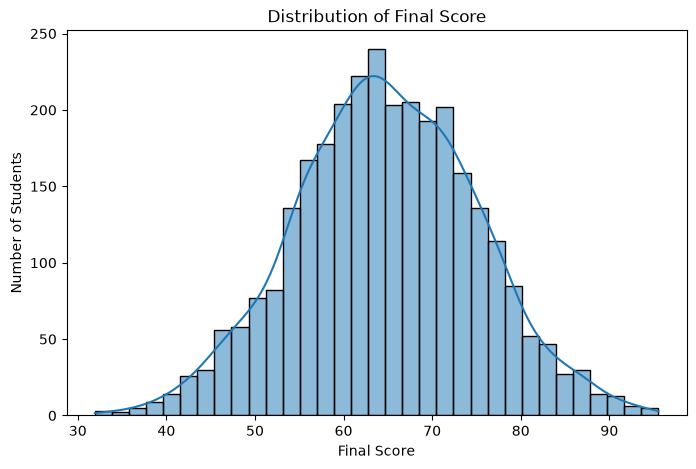

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(df["Final_Score"], kde=True)

plt.title("Distribution of Final Score")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()

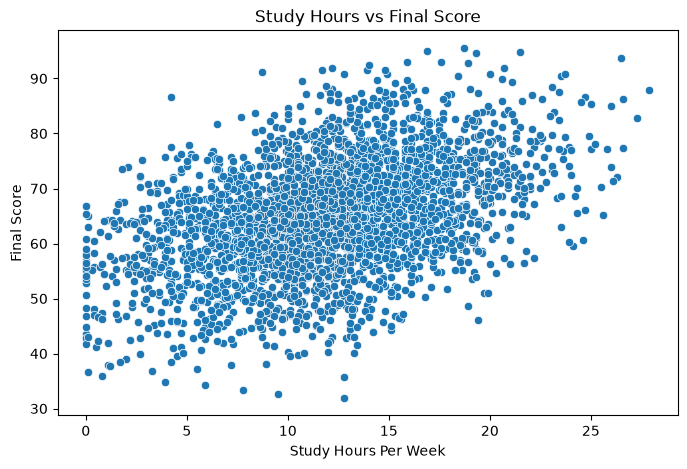

In [23]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df["Study_Hours_Per_Week"],
    y=df["Final_Score"]
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Final Score")

plt.show()

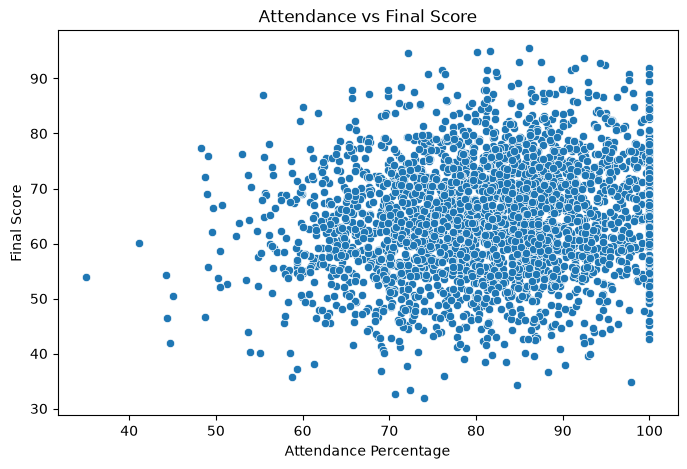

In [24]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df["Attendance_Percentage"],
    y=df["Final_Score"]
)

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")

plt.show()

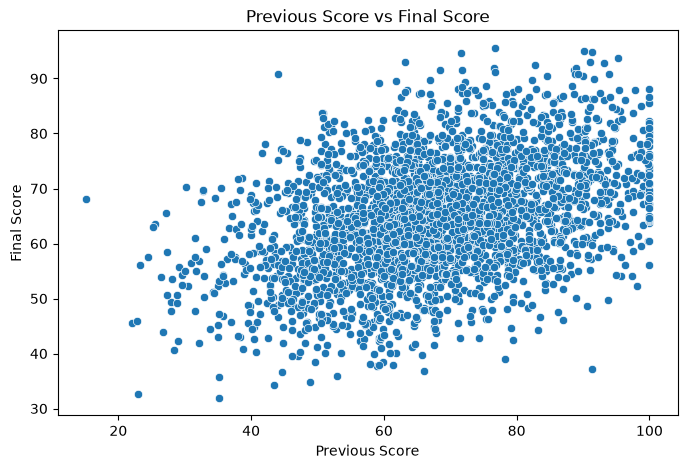

In [25]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df["Previous_Score"],
    y=df["Final_Score"]
)

plt.title("Previous Score vs Final Score")
plt.xlabel("Previous Score")
plt.ylabel("Final Score")

plt.show()

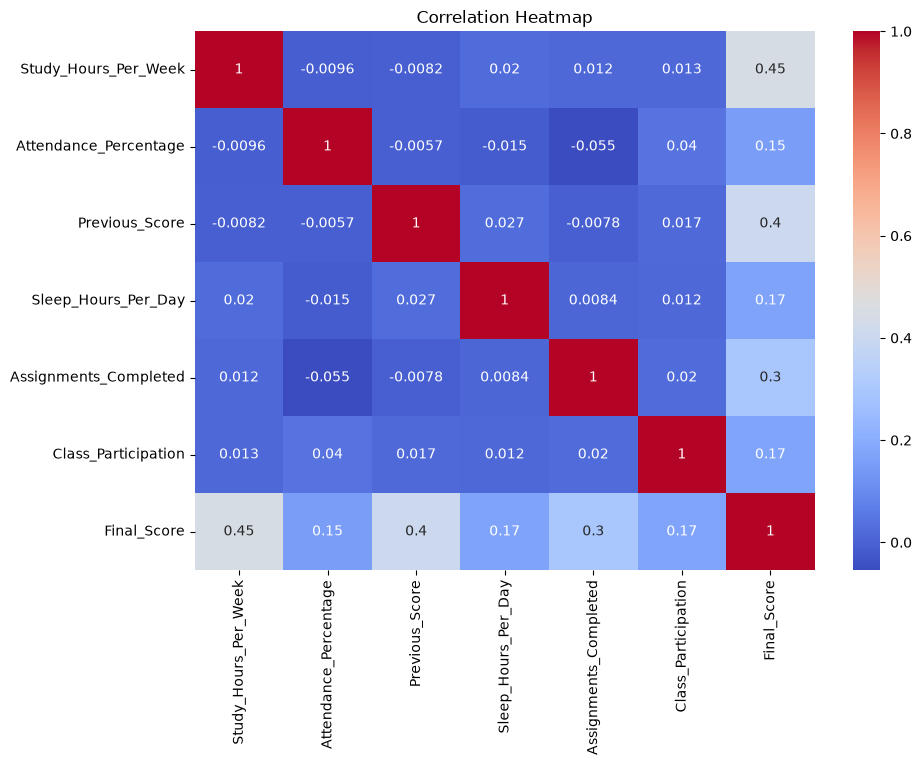

In [26]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [43]:
X = df.drop(
    ["Student_ID", "Final_Score"],
    axis=1
)

y = df["Final_Score"]

In [29]:
X.dtypes

Study_Hours_Per_Week          float64
Attendance_Percentage         float64
Previous_Score                float64
Sleep_Hours_Per_Day           float64
Assignments_Completed           int64
Class_Participation             int64
Internet_Access                   str
Extracurricular_Activities        str
dtype: object

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2400, 8)
(600, 8)
(2400,)
(600,)


In [45]:
X_train = pd.get_dummies(
    X_train,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True
)

In [35]:
X_train.head()

,Study_Hours_Per_Week,Attendance_Percentage,Previous_Score,Sleep_Hours_Per_Day,Assignments_Completed,Class_Participation,Internet_Access_Yes,Extracurricular_Activities_Yes
642,22.3,80.9,59.5,6.3,0,4,True,False
700,17.6,81.4,56.2,6.4,9,8,True,True
226,24.6,71.0,67.5,5.5,0,6,True,True
1697,23.9,80.9,85.7,7.1,8,8,True,False
1010,5.8,86.3,46.2,8.0,7,6,True,True


In [36]:
X_train.dtypes

Study_Hours_Per_Week              float64
Attendance_Percentage             float64
Previous_Score                    float64
Sleep_Hours_Per_Day               float64
Assignments_Completed               int64
Class_Participation                 int64
Internet_Access_Yes                  bool
Extracurricular_Activities_Yes       bool
dtype: object

In [46]:
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

In [47]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

167
39


In [48]:
numeric_cols = [
    "Study_Hours_Per_Week",
    "Attendance_Percentage",
    "Previous_Score",
    "Sleep_Hours_Per_Day",
    "Assignments_Completed",
    "Class_Participation"
]

In [49]:
for col in numeric_cols:
    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

In [50]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


In [38]:
print(X_train.shape)
print(X_test.shape)

(2400, 8)
(600, 8)


In [41]:
X_train.isnull().sum()

Study_Hours_Per_Week              40
Attendance_Percentage             76
Previous_Score                    51
Sleep_Hours_Per_Day                0
Assignments_Completed              0
Class_Participation                0
Internet_Access_Yes                0
Extracurricular_Activities_Yes     0
dtype: int64

In [42]:
X_test.isnull().sum()

Study_Hours_Per_Week               9
Attendance_Percentage             17
Previous_Score                    13
Sleep_Hours_Per_Day                0
Assignments_Completed              0
Class_Participation                0
Internet_Access_Yes                0
Extracurricular_Activities_Yes     0
dtype: int64

In [51]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[0.91,0.16,0.28,...,0.75,3.26,1.09]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Study_Hours_Per_Week','Attendance_Percentage','Previous_Score',..., 'Class_Participation','Internet_Access_Yes', 'Extracurricular_Activities_Yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.386
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [52]:
y_pred = model.predict(X_test)

In [53]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 5.5710161510391965
MSE: 49.00104990845927
RMSE: 7.000074993059665
R² Score: 0.5455368931369822


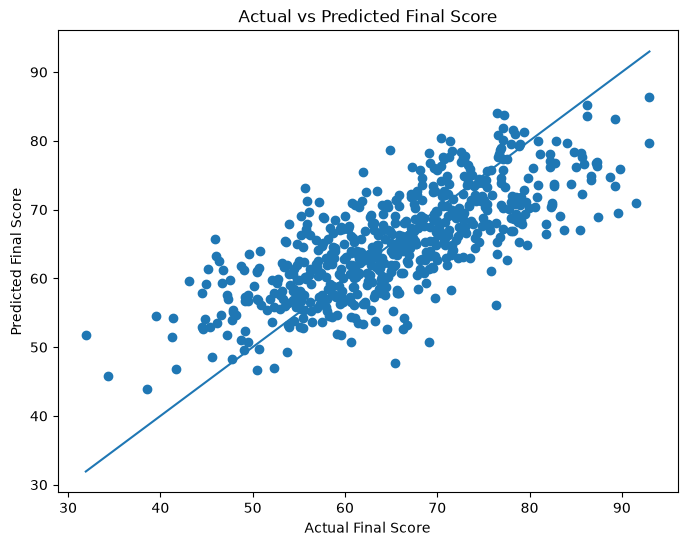

In [54]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted Final Score")

plt.show()

In [55]:
residuals = y_test - y_pred

In [56]:
residuals.head()

1801    10.551572
1190    -6.403567
1817    11.934288
251    -17.373666
2505     5.411225
Name: Final_Score, dtype: float64

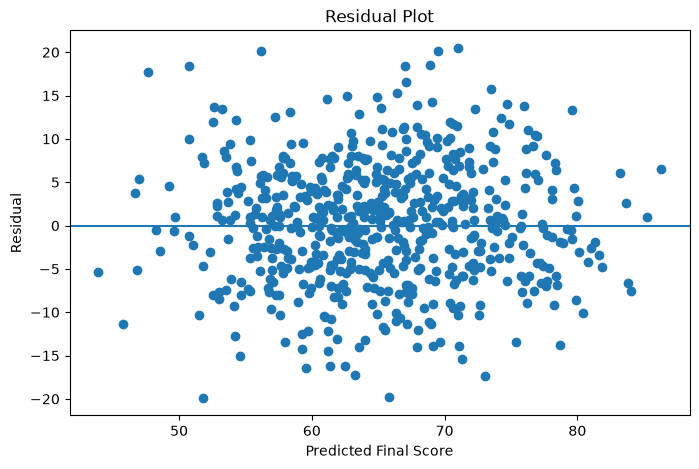

In [57]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0)

plt.xlabel("Predicted Final Score")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

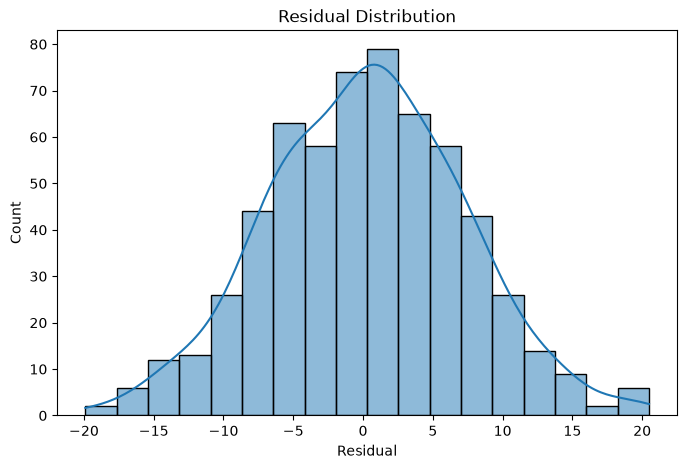

In [58]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residual")
plt.title("Residual Distribution")

plt.show()

In [59]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
6,Internet_Access_Yes,3.255317
3,Sleep_Hours_Per_Day,1.160090
7,Extracurricular_Activities_Yes,1.091867
4,Assignments_Completed,0.956077
0,Study_Hours_Per_Week,0.914944
5,Class_Participation,0.746679
2,Previous_Score,0.277180
1,Attendance_Percentage,0.158402


In [60]:
print("Intercept:", model.intercept_)

Intercept: 1.3864358165211854


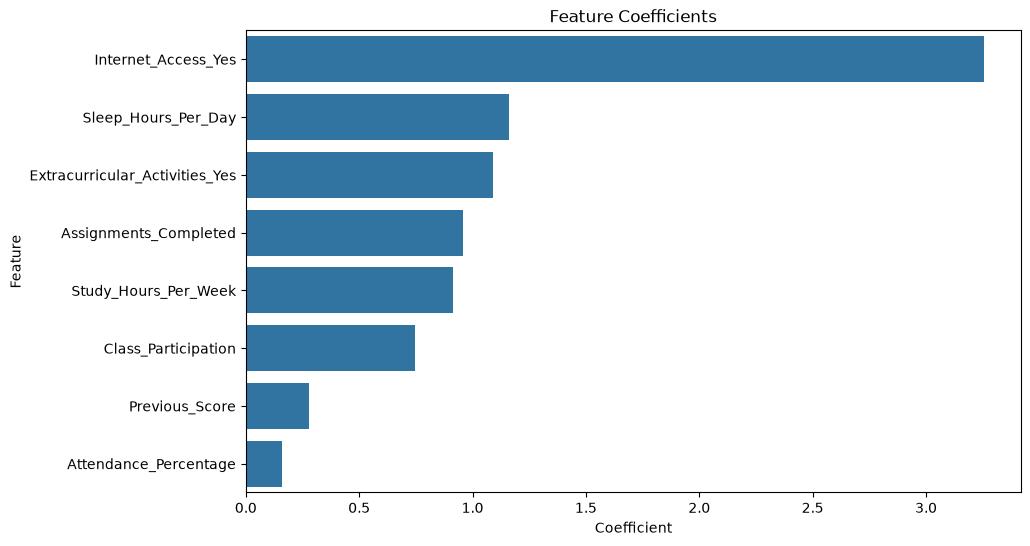

In [61]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [62]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

In [63]:
poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

In [64]:
poly_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Study_Hours_Per_Week','Attendance_Percentage','Previous_Score',..., 'Class_Participation','Internet_Access_Yes', 'Extracurricular_Activities_Yes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [65]:
poly_pred = poly_model.predict(X_test)

In [66]:
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_mse = mean_squared_error(y_test, poly_pred)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, poly_pred)

print("Polynomial MAE:", poly_mae)
print("Polynomial MSE:", poly_mse)
print("Polynomial RMSE:", poly_rmse)
print("Polynomial R²:", poly_r2)

Polynomial MAE: 5.628387810210497
Polynomial MSE: 49.8451779953301
Polynomial RMSE: 7.060111755158703
Polynomial R²: 0.5377079777634073


In [67]:
print("Linear Regression R²:", r2)
print("Polynomial Regression R²:", poly_r2)

Linear Regression R²: 0.5455368931369822
Polynomial Regression R²: 0.5377079777634073


In [68]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression"
    ],
    "MAE": [
        mae,
        poly_mae
    ],
    "MSE": [
        mse,
        poly_mse
    ],
    "RMSE": [
        rmse,
        poly_rmse
    ],
    "R2": [
        r2,
        poly_r2
    ]
})

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,5.571016,49.001050,7.000075,0.545537
1,Polynomial Regression,5.628388,49.845178,7.060112,0.537708


In [69]:
results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,5.571016,49.001050,7.000075,0.545537
1,Polynomial Regression,5.628388,49.845178,7.060112,0.537708


In [71]:
new_student = pd.DataFrame({
    "Study_Hours_Per_Week": [20],
    "Attendance_Percentage": [85],
    "Previous_Score": [75],
    "Sleep_Hours_Per_Day": [7],
    "Assignments_Completed": [8],
    "Class_Participation": [7],
    "Internet_Access_Yes": [1],
    "Extracurricular_Activities_Yes": [1]
})

In [72]:
new_student = new_student.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [73]:
predicted_score = model.predict(new_student)

print("Predicted Final Score:", predicted_score[0])

Predicted Final Score: 79.28119784242512
